# Olist Late Delivery Prediction

Predict whether an order will be delivered **after** its promised `order_estimated_delivery_date`, using only information available **at the moment of purchase**. This simulates a real "flag at-risk orders at checkout" use case, so any feature that only becomes known after purchase (approval time, carrier handoff, shipping limit, reviews) is deliberately excluded.


## 1. Setup

In [24]:
import sys, subprocess

for pkg in ["xgboost", "lightgbm", "shap"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    f1_score, RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay,
)

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)


## 2. Load & join data

Each raw table is loaded, aggregated to one row per `order_id` where needed, then joined onto the orders table. The geolocation table (61MB of raw lat/lng pings) is collapsed to one centroid per zip prefix *before* joining, since that's all we need for a buyer–seller distance feature.

In [26]:
orders = pd.read_csv("olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
])
order_items = pd.read_csv("olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")
geolocation = pd.read_csv("olist_geolocation_dataset.csv")
cat_translation = pd.read_csv("product_category_name_translation.csv")

print({name: df.shape for name, df in [
    ("orders", orders), ("order_items", order_items), ("customers", customers),
    ("sellers", sellers), ("products", products), ("payments", payments),
    ("geolocation", geolocation), ("cat_translation", cat_translation),
]})


{'orders': (99441, 8), 'order_items': (112650, 7), 'customers': (99441, 5), 'sellers': (3095, 4), 'products': (32951, 9), 'payments': (103886, 5), 'geolocation': (1000163, 5), 'cat_translation': (71, 2)}


In [27]:
# Zip-prefix centroid (mean lat/lng), used for buyer<->seller distance
geo_centroid = (
    geolocation.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
    .mean()
    .reset_index()
    .rename(columns={"geolocation_zip_code_prefix": "zip_code_prefix"})
)

products = products.merge(cat_translation, on="product_category_name", how="left")
products["product_category_name_english"] = products["product_category_name_english"].fillna(
    products["product_category_name"]
)
products["product_volume_cm3"] = (
    products["product_length_cm"] * products["product_height_cm"] * products["product_width_cm"]
)

# Order-item level, enriched with product attributes, then aggregated to one row per order
items = order_items.merge(
    products[["product_id", "product_category_name_english", "product_weight_g", "product_volume_cm3"]],
    on="product_id", how="left",
)

item_agg = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_distinct_products=("product_id", "nunique"),
    n_distinct_sellers=("seller_id", "nunique"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    avg_product_weight_g=("product_weight_g", "mean"),
    avg_product_volume_cm3=("product_volume_cm3", "mean"),
).reset_index()

# Dominant product category per order (by item count)
top_category = (
    items.groupby(["order_id", "product_category_name_english"]).size()
    .reset_index(name="cnt")
    .sort_values(["order_id", "cnt"], ascending=[True, False])
    .drop_duplicates("order_id")[["order_id", "product_category_name_english"]]
    .rename(columns={"product_category_name_english": "main_category"})
)
item_agg = item_agg.merge(top_category, on="order_id", how="left")

# First seller per order (for distance / seller-state features); most orders have exactly one seller
first_seller = (
    order_items.sort_values("order_item_id").drop_duplicates("order_id")[["order_id", "seller_id"]]
)
item_agg = item_agg.merge(first_seller, on="order_id", how="left")


In [28]:
payment_agg = payments.groupby("order_id").agg(
    total_payment_value=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
    n_payment_methods=("payment_sequential", "nunique"),
).reset_index()

dominant_payment_type = (
    payments.sort_values("payment_value", ascending=False).drop_duplicates("order_id")[["order_id", "payment_type"]]
)
payment_agg = payment_agg.merge(dominant_payment_type, on="order_id", how="left")


In [29]:
df = orders.merge(item_agg, on="order_id", how="left")
df = df.merge(payment_agg, on="order_id", how="left")
df = df.merge(customers, on="customer_id", how="left")
df = df.merge(
    sellers.rename(columns={"seller_zip_code_prefix": "seller_zip_code_prefix_",
                             "seller_city": "seller_city", "seller_state": "seller_state"}),
    on="seller_id", how="left",
)

df = df.merge(
    geo_centroid.rename(columns={"zip_code_prefix": "customer_zip_code_prefix",
                                   "geolocation_lat": "customer_lat", "geolocation_lng": "customer_lng"}),
    on="customer_zip_code_prefix", how="left",
)
df = df.merge(
    geo_centroid.rename(columns={"zip_code_prefix": "seller_zip_code_prefix_",
                                   "geolocation_lat": "seller_lat", "geolocation_lng": "seller_lng"}),
    on="seller_zip_code_prefix_", how="left",
)

print(df.shape)
df.head()


(99441, 32)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,n_items,n_distinct_products,n_distinct_sellers,total_price,total_freight,avg_product_weight_g,avg_product_volume_cm3,main_category,seller_id,total_payment_value,max_installments,n_payment_methods,payment_type,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,seller_zip_code_prefix_,seller_city,seller_state,customer_lat,customer_lng,seller_lat,seller_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.0,1.0,1.0,29.99,8.72,500.0,1976.0,housewares,3504c0cb71d7fa48d967e0e4c94d59d9,38.71,1.0,3.0,voucher,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,9350.0,maua,SP,-23.576983,-46.587161,-23.680729,-46.444238
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.0,1.0,1.0,118.70,22.76,400.0,4693.0,perfumery,289cdb325fb7e7f891c38608bf9e0962,141.46,1.0,1.0,boleto,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,31570.0,belo horizonte,SP,-12.177924,-44.660711,-19.807681,-43.980427
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.0,1.0,1.0,159.90,19.22,420.0,9576.0,auto,4869f7a5dfa277a7dca6462dcf3b52b2,179.12,3.0,1.0,credit_card,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,14840.0,guariba,SP,-16.745150,-48.514783,-21.363502,-48.229601
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.0,1.0,1.0,45.00,27.20,450.0,6000.0,pet_shop,66922902710d126a0e7d26b0e3805106,72.20,1.0,1.0,credit_card,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,31842.0,belo horizonte,MG,-5.774190,-35.271143,-19.837682,-43.924053
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.0,1.0,1.0,19.90,8.72,250.0,11475.0,stationery,2c9e548be18521d1c43cde1c582c6de8,28.62,1.0,1.0,credit_card,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,8752.0,mogi das cruzes,SP,-23.676370,-46.514627,-23.543395,-46.262086


## 3. Label: `is_late`

Restricted to `order_status == 'delivered'`, since lateness is undefined for cancelled / unavailable / still-in-transit orders.

In [30]:
df = df[df["order_status"] == "delivered"].copy()
df = df.dropna(subset=["order_delivered_customer_date", "order_estimated_delivery_date", "order_purchase_timestamp"])

df["is_late"] = (df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]).astype(int)

late_rate = df["is_late"].mean()
print(f"Delivered orders: {len(df):,}")
print(f"Late rate: {late_rate:.2%}")


Delivered orders: 96,470
Late rate: 8.11%


## 4. Exploratory data analysis

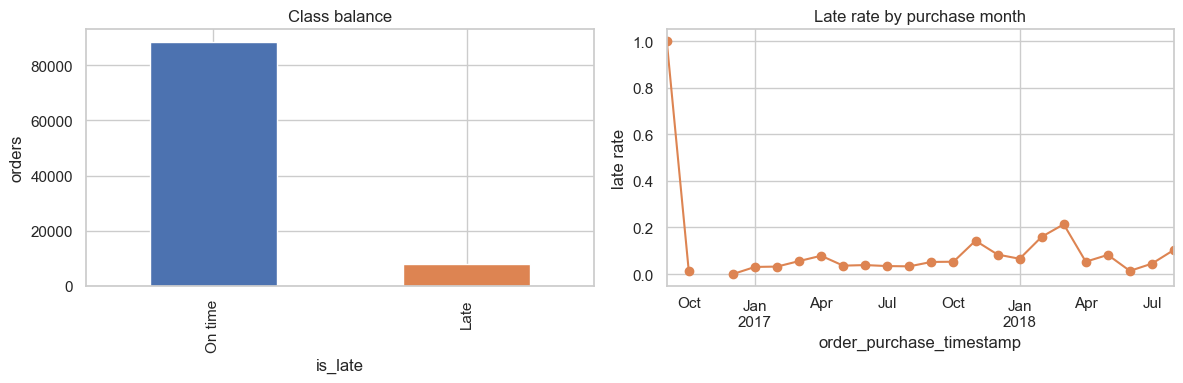

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["is_late"].value_counts().rename({0: "On time", 1: "Late"}).plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"]
)
axes[0].set_title("Class balance")
axes[0].set_ylabel("orders")

by_month = df.set_index("order_purchase_timestamp")["is_late"].resample("MS").mean()
by_month.plot(ax=axes[1], marker="o", color="#DD8452")
axes[1].set_title("Late rate by purchase month")
axes[1].set_ylabel("late rate")

plt.tight_layout()
plt.show()


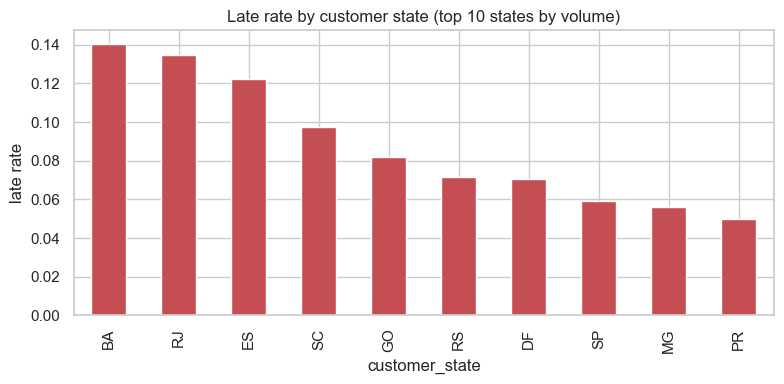

In [32]:
top_states = df["customer_state"].value_counts().head(10).index
late_by_state = df[df["customer_state"].isin(top_states)].groupby("customer_state")["is_late"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
late_by_state.plot(kind="bar", color="#C44E52")
plt.title("Late rate by customer state (top 10 states by volume)")
plt.ylabel("late rate")
plt.tight_layout()
plt.show()


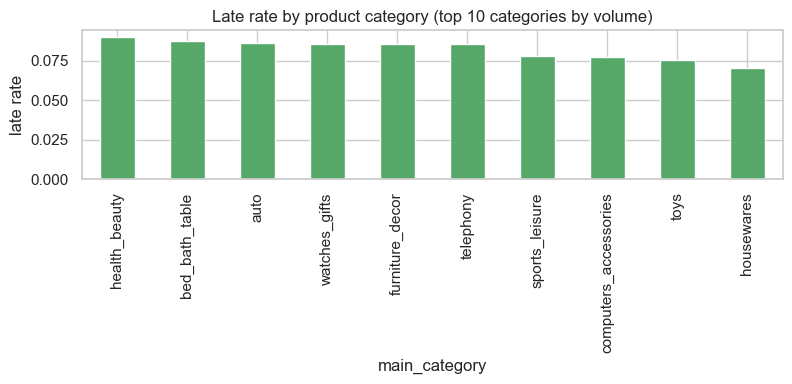

In [33]:
top_categories = df["main_category"].value_counts().head(10).index
late_by_cat = df[df["main_category"].isin(top_categories)].groupby("main_category")["is_late"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
late_by_cat.plot(kind="bar", color="#55A868")
plt.title("Late rate by product category (top 10 categories by volume)")
plt.ylabel("late rate")
plt.tight_layout()
plt.show()


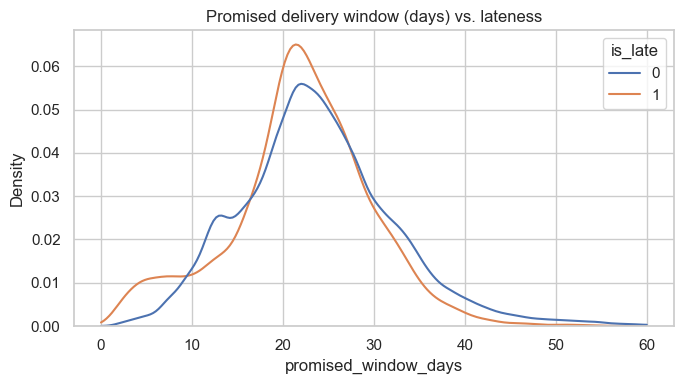

In [34]:
df["promised_window_days"] = (
    df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

plt.figure(figsize=(7, 4))
sns.kdeplot(data=df, x="promised_window_days", hue="is_late", common_norm=False, clip=(0, 60))
plt.title("Promised delivery window (days) vs. lateness")
plt.tight_layout()
plt.show()


## 5. Feature engineering (purchase-time only)

Only columns knowable at `order_purchase_timestamp` are used. The following are explicitly **excluded** because they are only known after purchase: `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `shipping_limit_date`, and anything from the reviews table (never loaded).

In [35]:
EXCLUDED_POST_PURCHASE_COLS = {
    "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "shipping_limit_date",
}

def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat, dlng = lat2 - lat1, lng2 - lng1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlng / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df["buyer_seller_distance_km"] = haversine_km(
    df["customer_lat"], df["customer_lng"], df["seller_lat"], df["seller_lng"]
)
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)

ts = df["order_purchase_timestamp"]
df["purchase_dow"] = ts.dt.dayofweek
df["purchase_month"] = ts.dt.month
df["purchase_is_weekend"] = ts.dt.dayofweek.isin([5, 6]).astype(int)
df["purchase_is_holiday_season"] = ts.dt.month.isin([11, 12]).astype(int)

df["freight_ratio"] = df["total_freight"] / df["total_price"].replace(0, np.nan)

FEATURE_COLS = [
    "promised_window_days", "n_items", "n_distinct_products", "n_distinct_sellers",
    "total_price", "total_freight", "freight_ratio",
    "avg_product_weight_g", "avg_product_volume_cm3",
    "main_category", "customer_state", "seller_state", "same_state",
    "buyer_seller_distance_km",
    "total_payment_value", "max_installments", "n_payment_methods", "payment_type",
    "purchase_dow", "purchase_month", "purchase_is_weekend", "purchase_is_holiday_season",
]

assert not (set(FEATURE_COLS) & EXCLUDED_POST_PURCHASE_COLS), "Leakage: post-purchase column in features!"

NUMERIC_FEATURES = [c for c in FEATURE_COLS if df[c].dtype.kind in "if"]
CATEGORICAL_FEATURES = [c for c in FEATURE_COLS if c not in NUMERIC_FEATURES]
print("Numeric:", NUMERIC_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)


Numeric: ['promised_window_days', 'n_items', 'n_distinct_products', 'n_distinct_sellers', 'total_price', 'total_freight', 'freight_ratio', 'avg_product_weight_g', 'avg_product_volume_cm3', 'same_state', 'buyer_seller_distance_km', 'total_payment_value', 'max_installments', 'n_payment_methods', 'purchase_dow', 'purchase_month', 'purchase_is_weekend', 'purchase_is_holiday_season']
Categorical: ['main_category', 'customer_state', 'seller_state', 'payment_type']


## 6. Train/test split

A **time-based** split (train on earlier purchases, test on the most recent slice) better simulates real deployment than a random split, since in production you always train on the past and predict the future.

In [36]:
df_sorted = df.sort_values("order_purchase_timestamp")
split_idx = int(len(df_sorted) * 0.8)
train_df = df_sorted.iloc[:split_idx]
test_df = df_sorted.iloc[split_idx:]

print(f"Train: {len(train_df):,} orders ({train_df['order_purchase_timestamp'].min().date()} to {train_df['order_purchase_timestamp'].max().date()})")
print(f"Test:  {len(test_df):,} orders ({test_df['order_purchase_timestamp'].min().date()} to {test_df['order_purchase_timestamp'].max().date()})")
print(f"Train late rate: {train_df['is_late'].mean():.2%} | Test late rate: {test_df['is_late'].mean():.2%}")

X_train, y_train = train_df[FEATURE_COLS], train_df["is_late"]
X_test, y_test = test_df[FEATURE_COLS], test_df["is_late"]


Train: 77,176 orders (2016-09-15 to 2018-05-26)
Test:  19,294 orders (2018-05-26 to 2018-08-29)
Train late rate: 8.82% | Test late rate: 5.29%


## 7. Baselines & models

In [37]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), CATEGORICAL_FEATURES),
])

models = {
    "majority_baseline": DummyClassifier(strategy="most_frequent"),
    "logistic_regression": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "random_forest": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(
            n_estimators=300, max_depth=12, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1,
        )),
    ]),
    "hist_gradient_boosting": Pipeline([
        ("prep", preprocess),
        ("clf", HistGradientBoostingClassifier(
            max_iter=300, class_weight="balanced", random_state=RANDOM_STATE,
        )),
    ]),
}

if HAS_XGB:
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    models["xgboost"] = Pipeline([
        ("prep", preprocess),
        ("clf", xgb.XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05,
            scale_pos_weight=scale_pos_weight, eval_metric="aucpr",
            random_state=RANDOM_STATE, n_jobs=-1,
        )),
    ])

fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    print(f"fitted: {name}")


fitted: majority_baseline
fitted: logistic_regression
fitted: random_forest


TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

## 8. Evaluation

The classes are imbalanced (late orders are the minority), so **PR-AUC and F1 are the primary metrics**; ROC-AUC and the confusion matrix are reported as secondary context. Accuracy alone would be misleading here (a model that always predicts "on time" gets a high accuracy but is useless).

In [ ]:
rows = []
for name, model in fitted.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = model.predict(X_test)
    y_pred = model.predict(X_test)
    rows.append({
        "model": name,
        "roc_auc": roc_auc_score(y_test, y_prob),
        "pr_auc": average_precision_score(y_test, y_prob),
        "f1": f1_score(y_test, y_pred),
    })

results = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
results


,model,roc_auc,pr_auc,f1
0,logistic_regression,0.727680,0.120144,0.174344
1,random_forest,0.557476,0.065603,0.097388
2,majority_baseline,0.500000,0.052918,0.000000


Best model by PR-AUC: logistic_regression
              precision    recall  f1-score   support

     on_time       0.96      0.77      0.86     18273
        late       0.11      0.48      0.17      1021

    accuracy                           0.76     19294
   macro avg       0.54      0.63      0.52     19294
weighted avg       0.92      0.76      0.82     19294



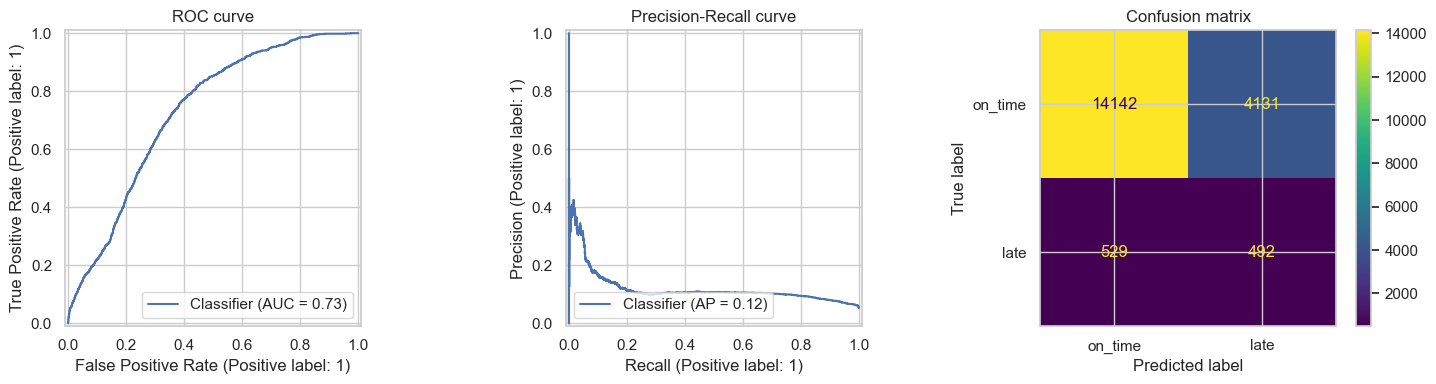

In [ ]:
best_name = results.iloc[0]["model"]
best_model = fitted[best_name]
print("Best model by PR-AUC:", best_name)

y_prob_best = best_model.predict_proba(X_test)[:, 1]
y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best, target_names=["on_time", "late"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_test, y_prob_best, ax=axes[0])
axes[0].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, y_prob_best, ax=axes[1])
axes[1].set_title("Precision-Recall curve")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=["on_time", "late"], ax=axes[2])
axes[2].set_title("Confusion matrix")
plt.tight_layout()
plt.show()


## 9. Interpretation — what drives predicted lateness?

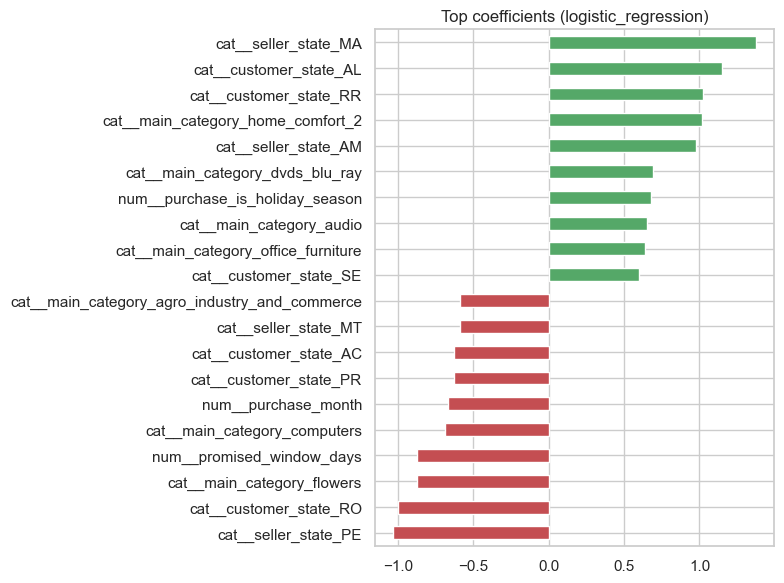

In [ ]:
clf = best_model.named_steps["clf"]
prep = best_model.named_steps["prep"]
feature_names = prep.get_feature_names_out()

if hasattr(clf, "feature_importances_"):
    importances = pd.Series(clf.feature_importances_, index=feature_names).sort_values(ascending=False).head(20)
    plt.figure(figsize=(8, 6))
    importances.sort_values().plot(kind="barh", color="#4C72B0")
    plt.title(f"Top 20 feature importances ({best_name})")
    plt.tight_layout()
    plt.show()
elif hasattr(clf, "coef_"):
    coefs = pd.Series(clf.coef_[0], index=feature_names).sort_values()
    top = pd.concat([coefs.head(10), coefs.tail(10)])
    plt.figure(figsize=(8, 6))
    top.plot(kind="barh", color=["#C44E52" if v < 0 else "#55A868" for v in top])
    plt.title(f"Top coefficients ({best_name})")
    plt.tight_layout()
    plt.show()


In [ ]:
if HAS_SHAP and hasattr(clf, "feature_importances_"):
    X_test_transformed = prep.transform(X_test)
    if hasattr(X_test_transformed, "toarray"):
        X_test_transformed = X_test_transformed.toarray()
    sample = X_test_transformed[:1000]

    explainer = shap.TreeExplainer(clf)
    shap_values = explainer.shap_values(sample)
    shap.summary_plot(shap_values, sample, feature_names=feature_names, show=True)
else:
    print("SHAP summary skipped (not installed or model type not tree-based).")


SHAP summary skipped (not installed or model type not tree-based).


## 10. Summary & caveats

- **Best model:** see `results` table above — compares majority-class baseline, logistic regression, random forest, HistGradientBoosting (and XGBoost if available) on PR-AUC, ROC-AUC, and F1.
- **Ceiling caveat:** because features are restricted to what's known at purchase time, the model cannot see the actual drivers of most delays (carrier delays, warehouse backlog, weather, holidays mid-transit). This caps achievable recall/precision — a model using post-purchase shipping events would score higher but couldn't be used to flag risk *at checkout*.
- **Top drivers** (from feature importance / SHAP above) typically include promised delivery window length, buyer–seller distance, customer state/region, and product category — consistent with the EDA findings.
- **Next steps:**
  - A second "in-transit" model (using `order_delivered_carrier_date` vs `shipping_limit_date`) could catch shipments that are *already* running late, for operational alerts rather than checkout-time risk scoring.
  - Hyperparameter tuning (e.g. `RandomizedSearchCV`) and probability calibration (`CalibratedClassifierCV`) if the output probabilities will be used to set an actionable risk threshold.
